# Commercial loss: which 100 addresses should inspectors visit next?

**Diagonally Ltd, Senior AI/ML Engineer assessment: exploratory notebook**

This notebook works from the raw files to a ranking one step at a time. Each step has three parts:

1. **Question**: what we are checking and why it matters.
2. **Code**: one small cell per step.
3. **Finding**: what the output shows and what we decide because of it (✅ confirmed / ❌ not confirmed / ⚠️ partly).

Before seeing the data we started with these claims to test:

| # | Claim | Tested in |
|---|---|---|
| H1 | The data is clean: no nulls, duplicates, or broken IDs | §2 |
| H2 | Bypass shows up as a sudden, sustained drop | §5.1 |
| H3 | A stuck meter shows up as repeated identical readings | §5.2 |
| H4 | Under-billing shows up as usage below peers | §5.3 |
| H5 | Tampering shows up as erratic readings | §5.4 |
| H6 | Vacant premises have low usage for legitimate reasons and must not be flagged | §6.1 |
| H7 | Some drops are genuine (not theft) | §6.2 |
| H8 | Labels can leak: behaviour after an inspection must not be used to evaluate it | §6.3 |
| H9 | Feeder losses help rank individual customers | §7 |
| H10 | Seasonality could make normal dips look like drops | §4 |

In [2]:
!pip install numpy pandas matplotlib seaborn scikit-learn

In [3]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path(os.environ.get("DATA_DIR", ".."))   # folder holding the four CSVs
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3})

## 1. Load the data and take a first look
**Question:** do the files match the brief (≈47k readings, 2,000 customers, 12 feeders, 250 labelled inspections)?

In [4]:
readings = pd.read_csv(DATA_DIR / "meter_readings.csv", parse_dates=["reading_date"])
customers = pd.read_csv(DATA_DIR / "customers.csv", parse_dates=["connection_date"])
feeders = pd.read_csv(DATA_DIR / "feeders.csv", parse_dates=["month"])
inspections = pd.read_csv(DATA_DIR / "inspections.csv", parse_dates=["inspection_date"])

for name, df in [("readings", readings), ("customers", customers),
                 ("feeders", feeders), ("inspections", inspections)]:
    print(f"{name:12s} {df.shape}")

readings     (46838, 8)
customers    (2000, 6)
feeders      (288, 3)
inspections  (280, 4)


In [5]:
readings.head()

,customer_id,meter_id,feeder_id,reading_date,kwh_billed,tariff_band,meter_type,account_status
0,C100000,M500000,F01,2024-09-01,1756.44,D1,prepaid,active
1,C100000,M500000,F01,2024-10-01,1691.63,D1,prepaid,active
2,C100000,M500000,F01,2024-11-01,1725.89,D1,prepaid,active
3,C100000,M500000,F01,2024-12-01,1682.46,D1,prepaid,active
4,C100000,M500000,F01,2025-01-01,1214.55,D1,prepaid,active


In [6]:
customers.head()

,customer_id,feeder_id,tariff_band,premises_type,meter_type,connection_date
0,C100000,F01,D1,industrial,prepaid,2024-09-01
1,C100001,F06,C1,commercial,prepaid,2024-09-01
2,C100002,F12,R2,residential,prepaid,2024-09-01
3,C100003,F10,R2,residential,postpaid,2024-09-01
4,C100004,F05,R2,residential,prepaid,2024-09-01


In [7]:
feeders.head()

,feeder_id,month,energy_delivered_kwh
0,F01,2024-09-01,66253.6
1,F01,2024-10-01,68994.6
2,F01,2024-11-01,66040.1
3,F01,2024-12-01,63968.2
4,F01,2025-01-01,54674.7


In [8]:
inspections.head()

,customer_id,inspection_date,outcome,loss_type
0,C100383,2025-07-01,clean,NaN
1,C101750,2025-06-01,clean,NaN
2,C100720,2025-01-01,clean,NaN
3,C101876,2025-04-01,clean,NaN
4,C101943,2025-04-01,theft_confirmed,bypass


In [9]:
print("Reading months :", readings.reading_date.min().date(), "->", readings.reading_date.max().date(),
      f"({readings.reading_date.nunique()} months)")
print("Connections    :", customers.connection_date.min().date(), "->", customers.connection_date.max().date())
print("Inspections    :", inspections.inspection_date.min().date(), "->", inspections.inspection_date.max().date())
print("Feeders        :", feeders.feeder_id.nunique(), "| feeder months:", feeders.month.nunique())
for col in ["tariff_band", "meter_type", "account_status"]:
    print(f"{col:15s}", readings[col].value_counts().to_dict())

Reading months : 2024-09-01 -> 2026-08-01 (24 months)
Connections    : 2024-09-01 -> 2026-04-01
Inspections    : 2024-12-01 -> 2025-08-01
Feeders        : 12 | feeder months: 24
tariff_band     {'R2': 34684, 'C1': 9651, 'D1': 2503}
meter_type      {'postpaid': 26087, 'prepaid': 20751}
account_status  {'active': 45731, 'vacant': 1107}


**Finding:** the files match the brief. There are 46,838 readings covering 24 months (Sep 2024 – Aug 2026), 2,000 customers, 12 feeders × 24 months, and 280 inspections (100 theft, 150 clean, 30 no-access).

One thing the brief doesn't mention: `account_status` has a **`vacant`** value on 1,107 readings. It becomes important in §6.1.

## 2. Data quality (H1)
**Question:** is anything broken that would silently corrupt features? We check nulls, duplicates, ID integrity, whether attributes agree between files, completeness, and impossible values.

In [10]:
for name, df in [("readings", readings), ("customers", customers),
                 ("feeders", feeders), ("inspections", inspections)]:
    print(f"{name:12s} nulls={df.isna().sum().to_dict()}  duplicate rows={df.duplicated().sum()}")

readings     nulls={'customer_id': 0, 'meter_id': 0, 'feeder_id': 0, 'reading_date': 0, 'kwh_billed': 0, 'tariff_band': 0, 'meter_type': 0, 'account_status': 0}  duplicate rows=0
customers    nulls={'customer_id': 0, 'feeder_id': 0, 'tariff_band': 0, 'premises_type': 0, 'meter_type': 0, 'connection_date': 0}  duplicate rows=0
feeders      nulls={'feeder_id': 0, 'month': 0, 'energy_delivered_kwh': 0}  duplicate rows=0
inspections  nulls={'customer_id': 0, 'inspection_date': 0, 'outcome': 0, 'loss_type': 180}  duplicate rows=0


In [11]:
print("duplicate customer-month readings :", readings.duplicated(["customer_id", "reading_date"]).sum())
print("duplicate customer ids            :", customers.customer_id.duplicated().sum())
print("customers inspected twice         :", inspections.customer_id.duplicated().sum())
print("readings for unknown customers    :", (~readings.customer_id.isin(customers.customer_id)).sum())
print("inspections for unknown customers :", (~inspections.customer_id.isin(customers.customer_id)).sum())
print("customers with no readings        :", (~customers.customer_id.isin(readings.customer_id)).sum())
print("customers with >1 meter           :", (readings.groupby("customer_id").meter_id.nunique() > 1).sum())

duplicate customer-month readings : 0
duplicate customer ids            : 0
customers inspected twice         : 0
readings for unknown customers    : 0
inspections for unknown customers : 0
customers with no readings        : 0
customers with >1 meter           : 0


In [12]:
# Do readings agree with the customer master on feeder, tariff and meter type?
chk = readings.merge(customers, on="customer_id", suffixes=("", "_master"))
for col in ["feeder_id", "tariff_band", "meter_type"]:
    print(f"{col:12s} mismatches: {(chk[col] != chk[col + '_master']).sum()}")
pd.crosstab(customers.premises_type, customers.tariff_band)

feeder_id    mismatches: 0
tariff_band  mismatches: 0
meter_type   mismatches: 0


tariff_band,C1,D1,R2
premises_type,,,
commercial,410,0,0
industrial,0,106,0
residential,0,0,1484


In [13]:
# Completeness: every month from connection to Aug 2026 present? any readings before connection?
last = readings.reading_date.max()
per_cust = readings.groupby("customer_id").reading_date.agg(["min", "max", "count"]).join(
    customers.set_index("customer_id").connection_date)
per_cust["expected"] = (last.year - per_cust.connection_date.dt.year) * 12 + (last.month - per_cust.connection_date.dt.month) + 1
print("customers with missing months      :", (per_cust["count"] < per_cust.expected).sum())
print("readings before connection date    :", (per_cust["min"] < per_cust.connection_date).sum())
print("customers whose data stops early   :", (per_cust["max"] < last).sum())

customers with missing months      : 0
readings before connection date    : 0
customers whose data stops early   : 0


In [14]:
# Can an inspection happen before the premises was connected?
insp_chk = inspections.merge(customers[["customer_id", "connection_date"]], on="customer_id")
bad_insp = insp_chk[insp_chk.inspection_date < insp_chk.connection_date]
print("inspections dated before connection:", len(bad_insp))
bad_insp

inspections dated before connection: 6


,customer_id,inspection_date,outcome,loss_type,connection_date
95,C101036,2025-04-01,clean,NaN,2026-01-01
115,C101399,2025-03-01,no_access,NaN,2025-09-01
160,C101196,2025-01-01,no_access,NaN,2025-05-01
252,C101406,2025-05-01,clean,NaN,2026-03-01
257,C100576,2025-06-01,no_access,NaN,2025-12-01
259,C101952,2024-12-01,clean,NaN,2026-04-01


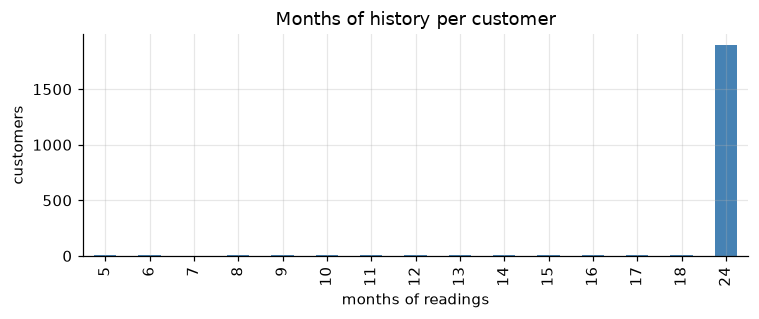

customers with < 12 months history: 40


In [15]:
fig, ax = plt.subplots(figsize=(7, 3))
per_cust["count"].value_counts().sort_index().plot.bar(ax=ax, color="steelblue")
ax.set(title="Months of history per customer", xlabel="months of readings", ylabel="customers")
plt.tight_layout(); plt.show()
print("customers with < 12 months history:", (per_cust["count"] < 12).sum())

In [16]:
print(per_cust["count"].value_counts().sort_index())
print("Customers with fewer than 12 months:", (per_cust["count"] < 12).sum())

count
5        5
6        5
7        1
8        9
9        8
10       5
11       7
12      10
13       6
14       8
15       8
16       9
17      11
18       8
24    1900
Name: count, dtype: int64
Customers with fewer than 12 months: 40


negative kWh: 0 | zero kWh: 0


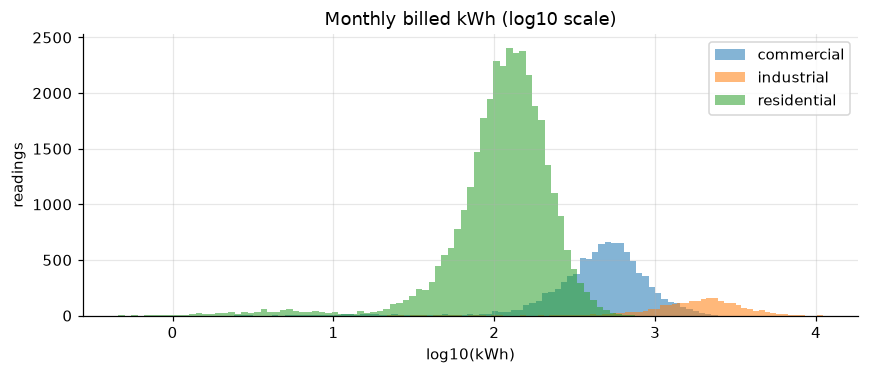

,count,mean,std,min,25%,50%,75%,max
premises_type,,,,,,,,
commercial,9651.0,544.9,327.5,1.8,327.1,487.7,685.0,2448.8
industrial,2503.0,2123.9,1325.5,14.1,1235.0,1915.6,2719.7,11014.1
residential,34684.0,135.4,77.0,0.5,83.7,122.2,172.8,753.7


In [17]:
print("negative kWh:", (readings.kwh_billed < 0).sum(), "| zero kWh:", (readings.kwh_billed == 0).sum())
r = readings.merge(customers[["customer_id", "premises_type"]], on="customer_id")
fig, ax = plt.subplots(figsize=(8, 3.5))
for pt, g in r.groupby("premises_type"):
    ax.hist(np.log10(g.kwh_billed), bins=80, alpha=.55, label=pt)
ax.set(title="Monthly billed kWh (log10 scale)", xlabel="log10(kWh)", ylabel="readings"); ax.legend()
plt.tight_layout(); plt.show()
r.groupby("premises_type").kwh_billed.describe().round(1)

In [18]:
# Feeder table: complete grid, and is billed ever more than delivered (impossible)?
print("feeder x month rows:", len(feeders), "expected:", 12 * 24)
billed = readings.groupby(["feeder_id", "reading_date"]).kwh_billed.sum().rename("billed")
fl = feeders.set_index(["feeder_id", "month"]).join(billed.rename_axis(["feeder_id", "month"]))
fl["loss_pct"] = 1 - fl.billed / fl.energy_delivered_kwh
print("months where billed > delivered:", (fl.loss_pct < 0).sum())
fl.loss_pct.describe().round(3)

feeder x month rows: 288 expected: 288
months where billed > delivered: 0


count    288.000
mean       0.109
std        0.035
min        0.045
25%        0.081
50%        0.103
75%        0.132
max        0.209
Name: loss_pct, dtype: float64

**Finding (H1 ⚠️, structurally clean with one real error):** there are no nulls, no duplicates, no orphan IDs, no missing months and no negative or zero values. The two files agree on every customer attribute, tariff maps one-to-one onto premises type (R2 = residential, C1 = commercial, D1 = industrial), and billed energy never exceeds delivered energy.

What does need handling:

- **6 inspections are dated before the customer was connected** (3 "clean", 3 "no_access"). You can't inspect a meter that doesn't exist yet, so either the date or the customer ID is wrong. *Decision: exclude these from every evaluation.* They are only 3 labels, but a model shouldn't learn from impossible records.
- **Scale:** industrial customers use about 15× more than residential ones. *Decision: compare every customer with their own history, never with raw kWh across types.*
- **Short histories:** 40 customers have less than a year of data (see the chart above). *Decision: a drop needs at least 3 months on each side before it counts.*
- **`vacant` status:** the brief doesn't mention it. Checked in §6.1.
- **The loss types don't come as data problems.** They show up as patterns in the readings (identical values, round numbers). §5 tests them.

## 3. The labels: what do the inspections tell us, and what don't they?
**Question:** how many labels are there, when are they from, and are they a fair sample?

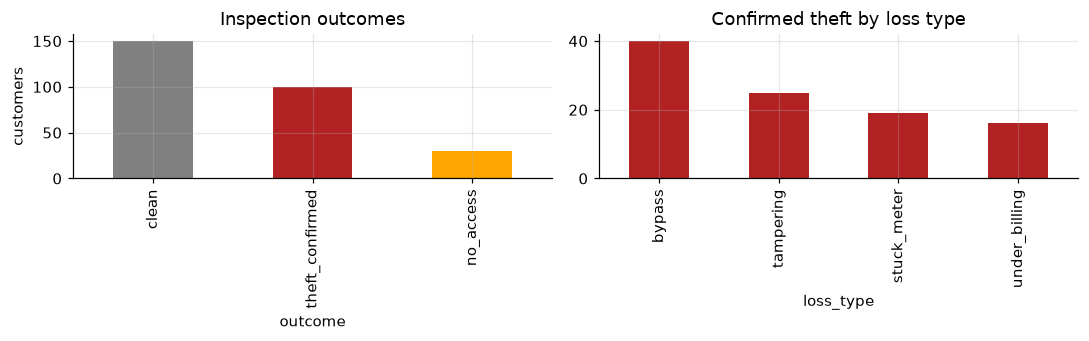

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
inspections.outcome.value_counts().plot.bar(ax=axes[0], color=["grey", "firebrick", "orange"])
axes[0].set(title="Inspection outcomes", ylabel="customers")
inspections.loss_type.value_counts().plot.bar(ax=axes[1], color="firebrick")
axes[1].set(title="Confirmed theft by loss type")
plt.tight_layout(); plt.show()

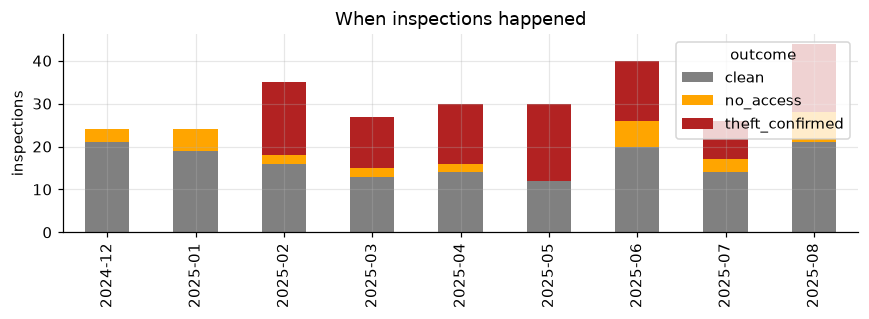

In [20]:
fig, ax = plt.subplots(figsize=(8, 3))
pd.crosstab(inspections.inspection_date.dt.strftime("%Y-%m"), inspections.outcome).plot.bar(stacked=True, ax=ax,
    color={"clean": "grey", "no_access": "orange", "theft_confirmed": "firebrick"})
ax.set(title="When inspections happened", xlabel="", ylabel="inspections")
plt.tight_layout(); plt.show()

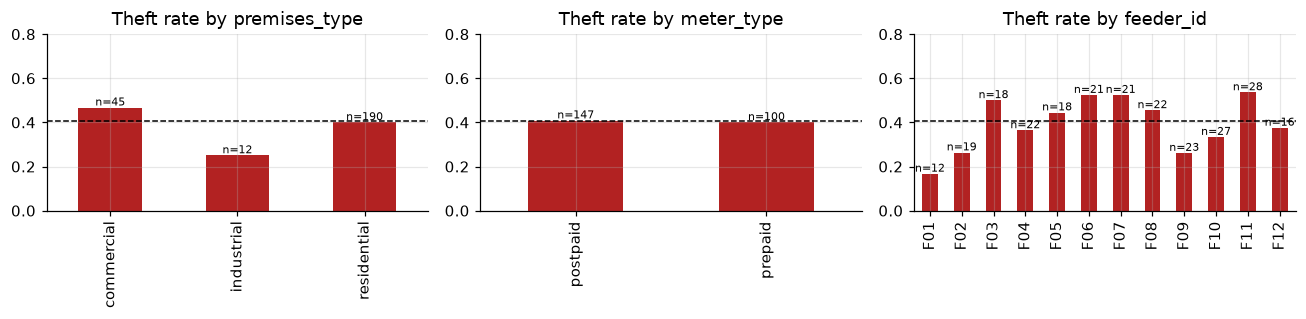

In [21]:
lab = inspections.merge(customers, on="customer_id")
lab = lab[(lab.outcome != "no_access") & ~lab.customer_id.isin(bad_insp.customer_id)].assign(theft=lambda d: d.outcome.eq("theft_confirmed"))
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, col in zip(axes, ["premises_type", "meter_type", "feeder_id"]):
    s = lab.groupby(col).theft.agg(["mean", "size"])
    s["mean"].plot.bar(ax=ax, color="firebrick")
    for i, (m, n) in enumerate(s.values): ax.text(i, m + .01, f"n={int(n)}", ha="center", fontsize=7)
    ax.axhline(lab.theft.mean(), ls="--", c="k", lw=1); ax.set(title=f"Theft rate by {col}", ylim=(0, .8), xlabel="")
plt.tight_layout(); plt.show()

**Finding:**

- **There are only 247 usable labels**: 100 theft and 147 clean. No-access is excluded because it means "unknown", not "clean", and so are the 3 impossible "clean" records from §2. The other 1,720 customers have never been inspected.
- **All inspections took place Dec 2024 – Aug 2025.** The readings run for another 12 months after that, so a label describes the customer **on the inspection date**, not today. This is the basis of §6.3.
- **Among inspected customers, 40% were thieves.** That is not the population rate. Inspectors chose whom to visit, presumably customers who already looked suspicious, so the labels are biased toward obvious cases.
- **No attribute predicts theft on its own.** Premises type, meter type and feeder all hover around the 40% line, and each feeder bar rests on 20 or fewer cases. *Decision: don't score customers on who they are. Score them on how their meter behaves.*

## 4. Normal behaviour and seasonality (H10)
**Question:** before looking for abnormal drops, what does normal month-to-month variation look like?

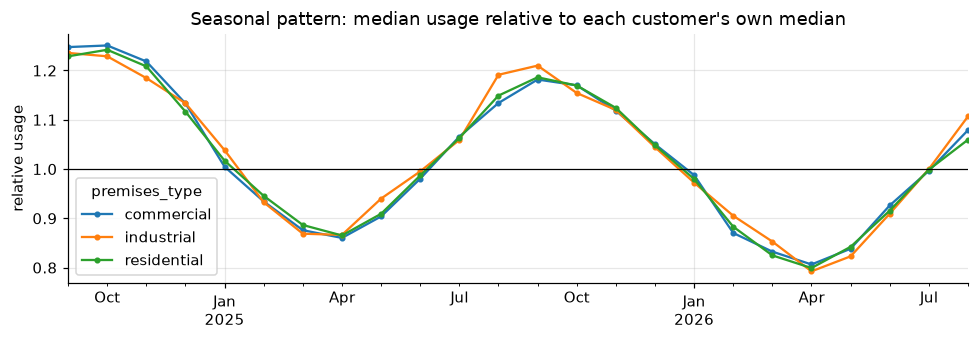

premises_type,commercial,industrial,residential
min,0.81,0.79,0.80
max,1.25,1.24,1.24


In [22]:
r = readings.merge(customers[["customer_id", "premises_type"]], on="customer_id")
r["rel"] = r.kwh_billed / r.groupby("customer_id").kwh_billed.transform("median")
season = r[r.account_status == "active"].groupby(["premises_type", "reading_date"]).rel.median().rename("season_idx")
fig, ax = plt.subplots(figsize=(9, 3.2))
season.unstack(0).plot(ax=ax, marker="o", ms=3)
ax.axhline(1, c="k", lw=.8); ax.set(title="Seasonal pattern: median usage relative to each customer's own median",
                                     ylabel="relative usage", xlabel="")
plt.tight_layout(); plt.show()
season.unstack(0).agg(["min", "max"]).round(2)

**Finding (H10 ✅):** usage swings about **±20% with the seasons** (high Sep–Nov, low around Mar–May), and all three premises types follow the same shape.

If we ignore this, every customer looks as if they dropped 30–40% each spring. *Decision: divide each reading by the seasonal index for its premises type and month (a "deseasonalised" series) before looking for drops.* The index is the median over all customers, so the small number of thieves can't distort it.

In [23]:
# Build the analysis matrices used for the rest of the notebook: one row per customer, one column per month.
r = r.join(season, on=["premises_type", "reading_date"])
r["deseason"] = r.kwh_billed / r.season_idx
raw = r.pivot(index="customer_id", columns="reading_date", values="kwh_billed")
status = r.pivot(index="customer_id", columns="reading_date", values="account_status")
deseason = r.pivot(index="customer_id", columns="reading_date", values="deseason")
months = raw.columns

label = inspections.set_index("customer_id")
group = label.loss_type.fillna(label.outcome).reindex(raw.index).fillna("uninspected")
insp_date = label.inspection_date.reindex(raw.index)
group.value_counts()

loss_type
uninspected      1720
clean             150
bypass             40
no_access          30
tampering          25
stuck_meter        19
under_billing      16
Name: count, dtype: int64

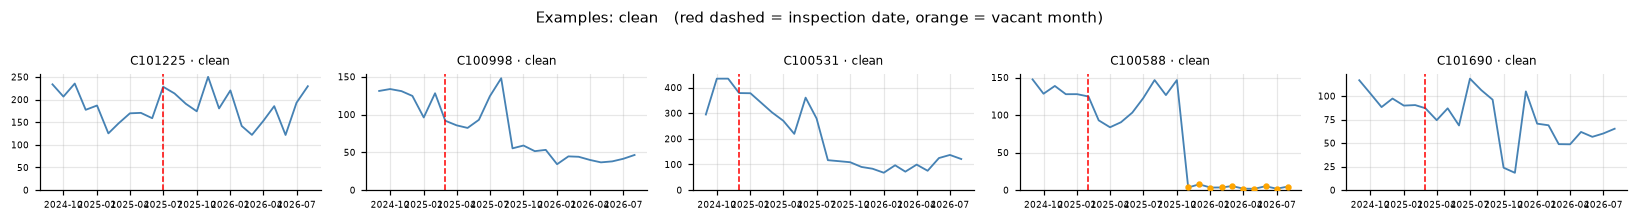

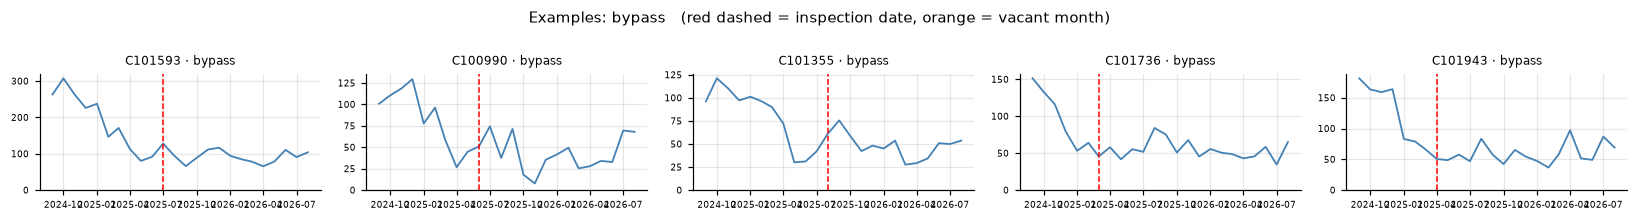

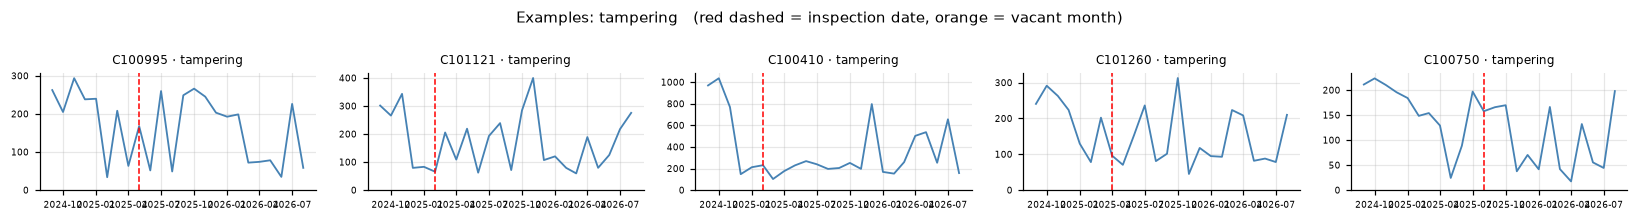

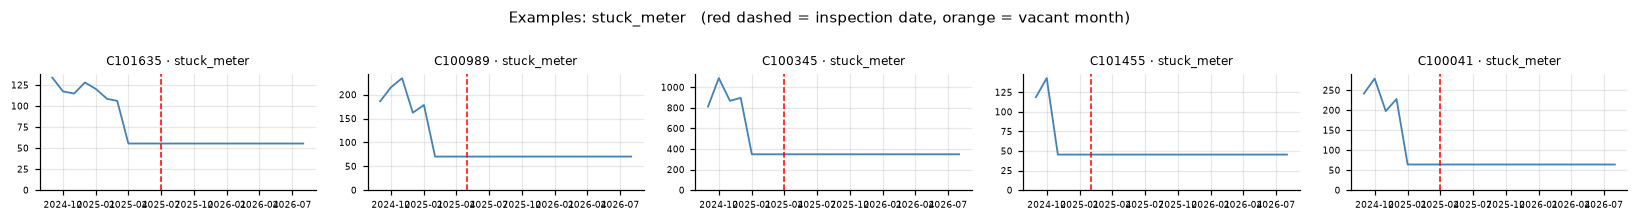

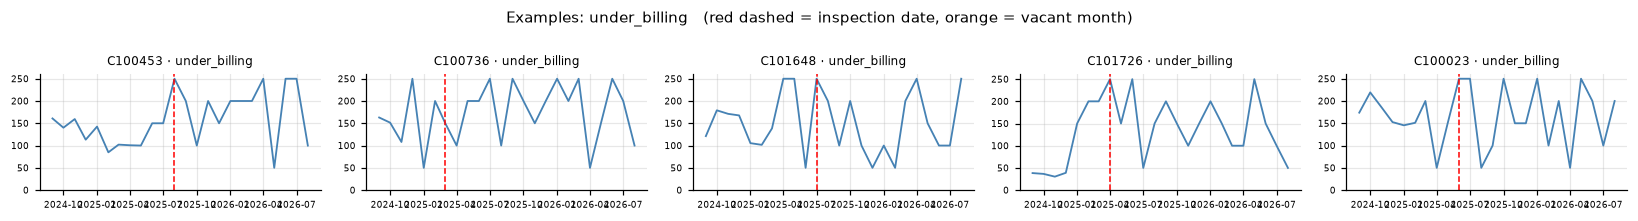

In [24]:
def plot_customers(ids, title, ncols=5):
    nrows = int(np.ceil(len(ids) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 2 * nrows), sharex=True, squeeze=False)
    for ax, cid in zip(axes.flat, ids):
        ax.plot(months, raw.loc[cid], c="steelblue", lw=1.2)
        vac = status.loc[cid] == "vacant"
        ax.scatter(months[vac], raw.loc[cid][vac], c="orange", s=10, zorder=3, label="vacant")
        if pd.notna(insp_date.get(cid)): ax.axvline(insp_date[cid], c="red", ls="--", lw=1)
        ax.set_title(f"{cid} · {group[cid]}", fontsize=8); ax.tick_params(labelsize=6); ax.set_ylim(bottom=0)
    for ax in axes.flat[len(ids):]: ax.axis("off")
    fig.suptitle(title + "   (red dashed = inspection date, orange = vacant month)", fontsize=10)
    plt.tight_layout(); plt.show()

rng = np.random.default_rng(0)
for g in ["clean", "bypass", "tampering", "stuck_meter", "under_billing"]:
    ids = rng.choice(group[group == g].index, 5, replace=False)
    plot_customers(list(ids), f"Examples: {g}")

**Finding: each loss type leaves a visibly different fingerprint.**

| Loss type | What the chart shows |
|---|---|
| **bypass** | A sudden drop to about half, staying low and **noisier** than before |
| **tampering** | Usage **switches on and off**: normal months mixed with very low ones |
| **stuck_meter** | An **exactly flat line**: the same value every month after onset |
| **under_billing** | Readings that are **round numbers (50, 100, 150, 200, 250)**, which look like estimated bills rather than meter reads |
| **clean** | Mostly stable, but some clean customers **also drop**, usually *after* their inspection (red line) |

Each of these is a hypothesis for now. §5 measures them across all customers.

## 5. Testing each loss-type claim

Each test builds one measurable feature, then compares its distribution across label groups. For the labelled customers, features are computed **only on data up to the inspection date** (point-in-time), so a label is compared with the behaviour the inspector actually saw. §6.3 shows why this matters.

In [25]:
def upto(cid, series_matrix, cutoff=None):
    """One customer's series, vacant months removed, optionally cut at a date (inclusive)."""
    s = series_matrix.loc[cid].where(status.loc[cid] == "active").dropna()
    return s if cutoff is None or pd.isna(cutoff) else s[s.index <= cutoff]

def pit_cutoff(cid):
    """Point-in-time cutoff: inspection date for labelled customers, none otherwise."""
    return insp_date.get(cid)

### 5.1 H2: bypass = sudden, sustained drop

**Feature:** for each possible split month, compare median (deseasonalised) usage after the split with median usage before it, and keep the split with the biggest drop. That gives `drop_pct` (the size), `onset` (when), and `noise_ratio` (how much more erratic the readings became after the drop, measured as a robust coefficient of variation).

In [26]:
def rcv(v):
    """Robust coefficient of variation: median absolute deviation / median."""
    med = np.median(v)
    return np.median(np.abs(v - med)) / med if med > 0 else np.nan

def step_drop(s, min_side=3):
    v = s.values
    best_ratio, best_k = 1.0, None
    for k in range(min_side, len(v) - min_side + 1):
        ratio = np.median(v[k:]) / np.median(v[:k])
        if ratio < best_ratio:
            best_ratio, best_k = ratio, k
    if best_k is None:
        return dict(drop_pct=0.0, onset=pd.NaT, months_after=0, noise_ratio=np.nan)
    before, after = v[:best_k], v[best_k:]
    return dict(drop_pct=1 - best_ratio, onset=s.index[best_k], months_after=len(after),
                noise_ratio=rcv(after) / max(rcv(before), 0.02))

drops_pit = pd.DataFrame({cid: step_drop(upto(cid, deseason, pit_cutoff(cid))) for cid in raw.index}).T
drops_pit = drops_pit.astype({"drop_pct": float, "months_after": float, "noise_ratio": float})
drops_pit["onset"] = pd.to_datetime(drops_pit.onset)
drops_pit["group"] = group
drops_pit.groupby("group")[["drop_pct", "noise_ratio"]].median().round(2)

,drop_pct,noise_ratio
group,,
bypass,0.54,1.02
clean,0.00,1.06
no_access,0.00,1.30
stuck_meter,0.64,0.64
tampering,0.56,2.98
under_billing,0.00,5.68
uninspected,0.05,1.20


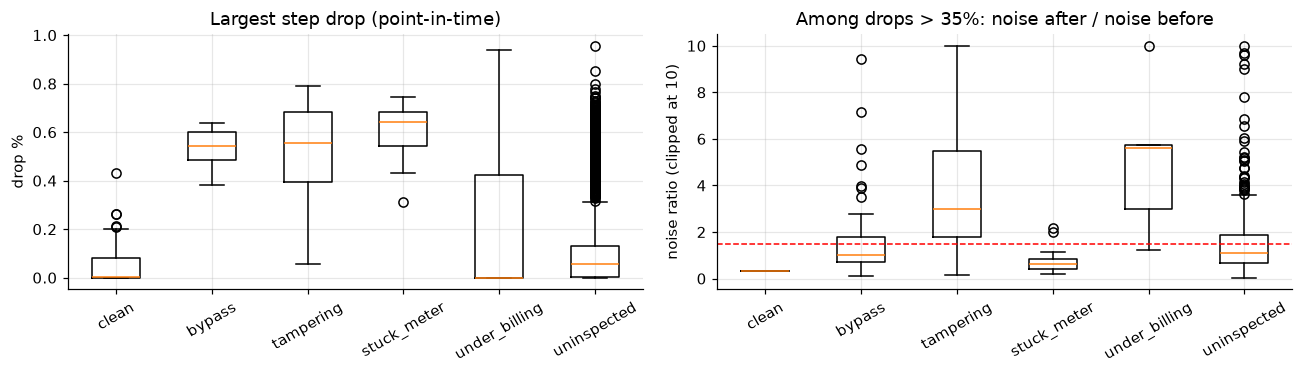

In [27]:
order = ["clean", "bypass", "tampering", "stuck_meter", "under_billing", "uninspected"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].boxplot([drops_pit.loc[drops_pit.group == g, "drop_pct"] for g in order], tick_labels=order)
axes[0].set(title="Largest step drop (point-in-time)", ylabel="drop %")
big = drops_pit[drops_pit.drop_pct > .35]
axes[1].boxplot([big.loc[big.group == g, "noise_ratio"].dropna().clip(upper=10) for g in order], tick_labels=order)
axes[1].axhline(1.5, c="r", ls="--", lw=1)
axes[1].set(title="Among drops > 35%: noise after / noise before", ylabel="noise ratio (clipped at 10)")
for ax in axes: ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

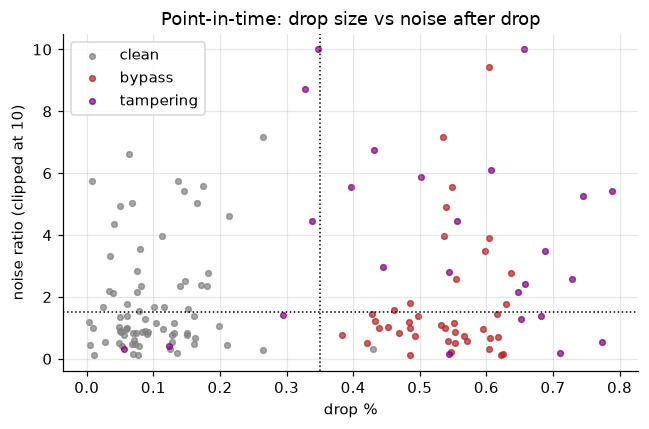

In [28]:
# Clean vs bypass scatter: can drop size alone separate them?
fig, ax = plt.subplots(figsize=(6, 4))
for g, c in [("clean", "grey"), ("bypass", "firebrick"), ("tampering", "purple")]:
    d = drops_pit[drops_pit.group == g]
    ax.scatter(d.drop_pct, d.noise_ratio.clip(upper=10), s=14, alpha=.7, c=c, label=g)
ax.axvline(.35, c="k", ls=":", lw=1); ax.axhline(1.5, c="k", ls=":", lw=1)
ax.set(xlabel="drop %", ylabel="noise ratio (clipped at 10)", title="Point-in-time: drop size vs noise after drop"); ax.legend()
plt.tight_layout(); plt.show()

**Finding (H2 ✅):** at inspection time, bypass customers show a median drop of **54%**, while clean customers' median is **0%**. When the inspector visited, clean customers simply hadn't dropped.

**Noise after the drop is not visible yet at inspection time.** The bypass median noise ratio is 1.02, about the same as clean, because the inspector arrived only about 3 months after onset. Tampering is already noisy (median 2.98). Whether bypass becomes noisier with more months, which is what would separate it from a genuine drop, is tested on the full history in §6.2.

### 5.2 H3: stuck meter = repeated identical readings

**Feature:** `stuck_run`, the longest run of consecutive, exactly identical billed values (vacant months excluded). Real meters reported to 2 decimal places almost never repeat by chance.

In [29]:
def longest_identical_run(s):
    v = s.values
    best = run = 1
    for a, b in zip(v[:-1], v[1:]):
        run = run + 1 if a == b else 1
        best = max(best, run)
    return best if len(v) else 0

stuck_pit = pd.Series({cid: longest_identical_run(upto(cid, raw, pit_cutoff(cid))) for cid in raw.index})
pd.crosstab(group, stuck_pit.clip(upper=6).rename("longest identical run (6 = 6+)"))

longest identical run (6 = 6+),0,1,2,3,4,5,6
loss_type,,,,,,,
bypass,0,39,1,0,0,0,0
clean,3,147,0,0,0,0,0
no_access,3,27,0,0,0,0,0
stuck_meter,0,0,0,0,19,0,0
tampering,0,25,0,0,0,0,0
under_billing,0,7,8,1,0,0,0
uninspected,0,1660,19,2,1,7,31


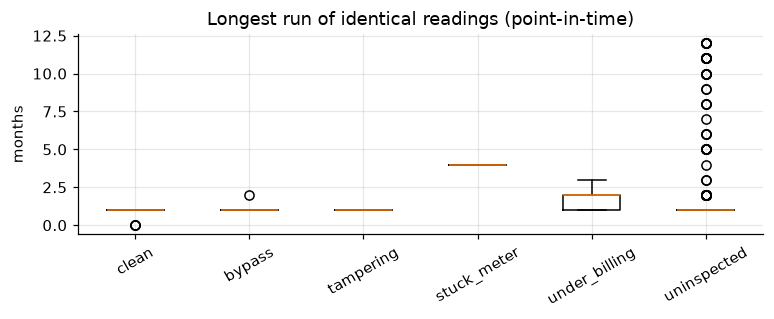

In [30]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.boxplot([stuck_pit[group == g] for g in order], tick_labels=order); ax.tick_params(axis="x", rotation=30)
ax.set(title="Longest run of identical readings (point-in-time)", ylabel="months")
plt.tight_layout(); plt.show()

**Finding (H3 ✅, strongly):** all 19 stuck-meter cases have a run of **4** identical readings at inspection time, and **no clean or bypass customer has more than 1–2**. This is the cleanest signal in the data.

- **41 uninspected customers** also have a run of 3 or more. Most have run for 6+ months, so these are likely stuck meters nobody has visited yet.
- **Under-billed accounts sometimes repeat a round value 2–3 times** (for example 200, 200). *Decision: count a run of 3+ as a stuck meter only when the bills are not round numbers, so each customer gets the right reason.*

### 5.3 H4: under-billing = usage below peers?

We planned to measure under-billing by comparing a customer's usage with their peers'. The charts in §4 suggested a different fingerprint, **round numbers**, so we test both:

- `round_share`: the share of readings that are exact multiples of 50 kWh.
- `peer_ratio`: recent median usage ÷ median usage of the same premises type.

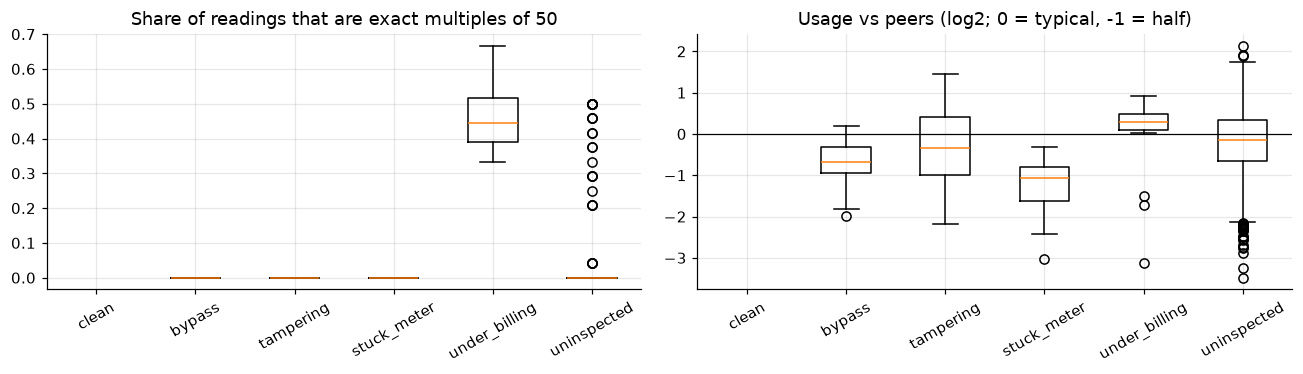

,round_share>0.2,n
loss_type,,
bypass,0,40
clean,0,150
no_access,0,30
stuck_meter,0,19
tampering,0,25
under_billing,16,16
uninspected,22,1720


In [31]:
round_pit = pd.Series({cid: (upto(cid, raw, pit_cutoff(cid)) % 50 == 0).mean() for cid in raw.index})
peer_med = r[r.account_status == "active"].groupby("premises_type").kwh_billed.median()
ptype = customers.set_index("customer_id").premises_type
peer_pit = pd.Series({cid: upto(cid, raw, pit_cutoff(cid)).tail(6).median() / peer_med[ptype[cid]] for cid in raw.index})

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].boxplot([round_pit[group == g] for g in order], tick_labels=order); axes[0].set(title="Share of readings that are exact multiples of 50")
axes[1].boxplot([np.log2(peer_pit[group == g]) for g in order], tick_labels=order); axes[1].axhline(0, c="k", lw=.8)
axes[1].set(title="Usage vs peers (log2; 0 = typical, -1 = half)")
for ax in axes: ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
pd.DataFrame({"round_share>0.2": (round_pit > .2).groupby(group).sum(), "n": group.value_counts()})

**Finding (H4 ❌ as originally stated, ✅ with the round-number fingerprint):**

- **Round numbers separate under-billing perfectly on the labels.** All 16 under-billing cases have more than 20% round bills, compared with zero in every other labelled group. Another **22 uninspected customers** show the same pattern. Under-billed accounts are billed round amounts (50–250 kWh), which looks like estimated rather than metered billing. Normal readings have decimals and are practically never exact multiples of 50.
- **Usage vs peers is a weak signal.** Residential under-billed accounts sit close to typical residential usage, and plenty of honest customers are simply small users. That is the brief's warning: *"not every customer with low consumption is a problem"*. *Decision: use round-number billing and drop the peer comparison as a primary signal.*

### 5.4 H5: tampering = erratic readings

**Feature:** `flips` counts how often usage switches between a "low" month (below 50% of the customer's normal level) and a normal month. Normal level is the 75th percentile of the customer's deseasonalised history, which theft months can't pull down. `low_months` counts the low months.

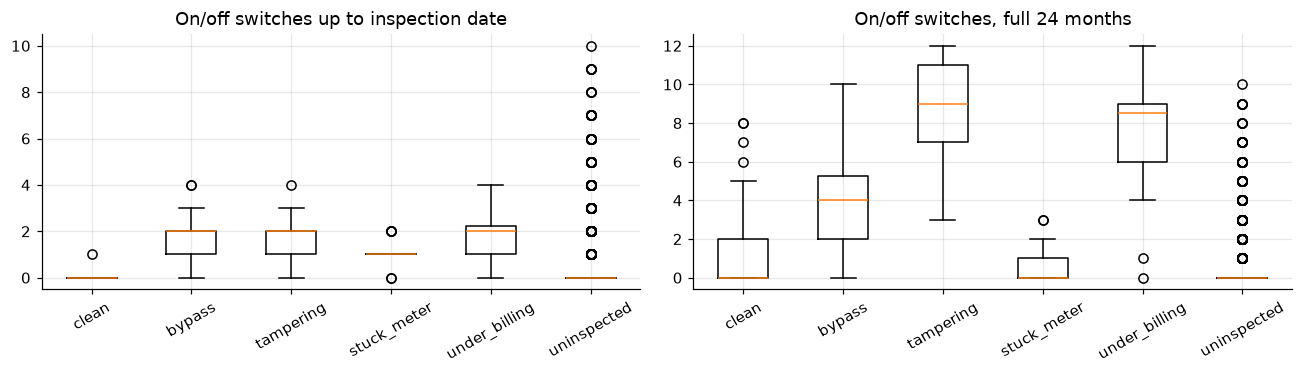

,median flips (point-in-time),median flips (full history),share with 4+ flips (full)
loss_type,,,
bypass,2.0,4.0,0.52
clean,0.0,0.0,0.09
no_access,0.0,0.0,0.00
stuck_meter,1.0,0.0,0.00
tampering,2.0,9.0,0.96
under_billing,2.0,8.5,0.88
uninspected,0.0,0.0,0.06


In [32]:
def on_off(s):
    v = s.values
    if len(v) < 4:
        return dict(flips=0, low_months=0)
    low = v < 0.5 * np.percentile(v, 75)
    return dict(flips=int((low[1:] != low[:-1]).sum()), low_months=int(low.sum()))

tamper_pit = pd.DataFrame({cid: on_off(upto(cid, deseason, pit_cutoff(cid))) for cid in raw.index}).T
tamper_full = pd.DataFrame({cid: on_off(upto(cid, deseason)) for cid in raw.index}).T
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].boxplot([tamper_pit.flips[group == g] for g in order], tick_labels=order)
axes[0].set(title="On/off switches up to inspection date")
axes[1].boxplot([tamper_full.flips[group == g] for g in order], tick_labels=order)
axes[1].set(title="On/off switches, full 24 months")
for ax in axes: ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
pd.DataFrame({"median flips (point-in-time)": tamper_pit.flips.groupby(group).median(),
              "median flips (full history)": tamper_full.flips.groupby(group).median(),
              "share with 4+ flips (full)": (tamper_full.flips >= 4).groupby(group).mean().round(2)})

**Finding (H5 ⚠️, true but slow to show):**

- **Over the full history, tampering stands out.** Its median is **9 switches** and 96% have 4 or more. Clean customers have a median of **0**; 9% reach 4+ but none goes above 8.
- **At inspection time the signal is weak.** The tampering median is only 2 switches, because tampering started a few months before the visit and there hadn't been time for many switches.
- **Under-billing and some noisy bypasses also switch** (median 8.5 and 4). That's fine, because they are theft as well.

*Decision: keep `flips` as a detector, scoring 0 at 3 switches and full strength at 7+. That sits above most clean customers, but a few clean ones will overlap. It works best on current data, where histories are long.*

## 6. The traps the brief warned about
### 6.1 H6: vacant premises

customers with vacant months: 120
their inspection outcomes   : {'uninspected': 113, 'clean': 6, 'no_access': 1}
usage while vacant, as share of their normal: median 3%


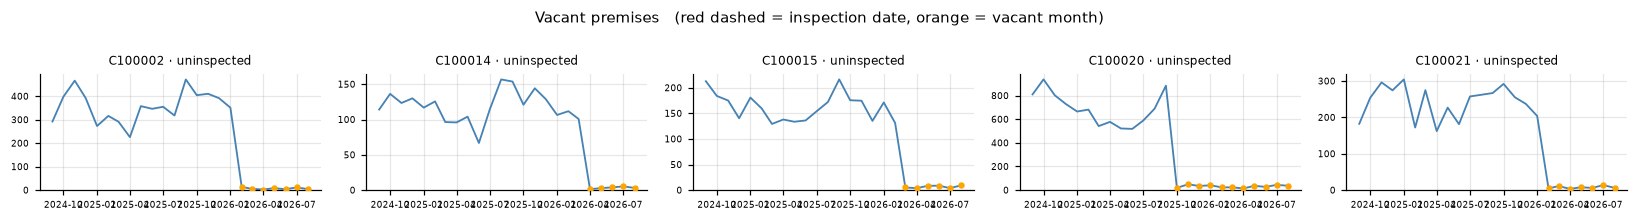

In [33]:
vac_ids = status.index[(status == "vacant").any(axis=1)]
print("customers with vacant months:", len(vac_ids))
print("their inspection outcomes   :", group[vac_ids].value_counts().to_dict())
vac_level = (raw.where(status == "vacant").median(axis=1) / raw.where(status == "active").median(axis=1))[vac_ids]
print(f"usage while vacant, as share of their normal: median {vac_level.median():.0%}")
plot_customers(list(vac_ids[:5]), "Vacant premises")

In [34]:
# Would a naive 'biggest raw drop' detector get fooled by vacancy?
naive = pd.DataFrame({cid: step_drop(raw.loc[cid].dropna()) for cid in raw.index}).T.drop_pct.astype(float)
top100_naive = naive.nlargest(100).index
print("naive raw-drop top 100 that are vacant premises:", top100_naive.isin(vac_ids).sum())

naive raw-drop top 100 that are vacant premises: 100


**Finding (H6 ✅):** 120 customers go vacant, and their usage falls to a few percent of normal. That is a *deeper* drop than any bypass. None of the inspected vacant customers were thieves.

A naive "largest drop" ranking fills most of its top 100 with empty premises, exactly the wasted visits the brief warns about. *Decision: remove vacant months before computing any feature.* A customer whose drop is explained entirely by vacancy then scores zero.

### 6.2 H7: genuine drops. Does noise separate them from bypass?

quiet drops by group: {'uninspected': 195, 'clean': 56, 'stuck_meter': 11, 'bypass': 7, 'tampering': 5, 'under_billing': 2, 'no_access': 1}
noisy drops by group: {'uninspected': 96, 'bypass': 32, 'tampering': 19, 'clean': 16, 'stuck_meter': 7, 'under_billing': 4, 'no_access': 2}


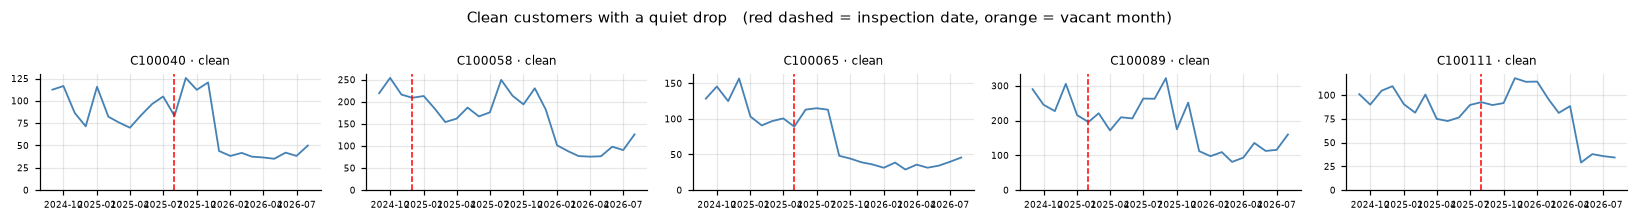

In [35]:
# Customers who dropped > 35% with *low* noise after the drop, over their full history.
drops_full = pd.DataFrame({cid: step_drop(upto(cid, deseason)) for cid in raw.index}).T
drops_full = drops_full.astype({"drop_pct": float, "months_after": float, "noise_ratio": float})
drops_full["onset"] = pd.to_datetime(drops_full.onset)
quiet_drop = drops_full[(drops_full.drop_pct > .35) & (drops_full.noise_ratio < 1.5)].index
noisy_drop = drops_full[(drops_full.drop_pct > .35) & (drops_full.noise_ratio >= 1.5)].index
print("quiet drops by group:", group[quiet_drop].value_counts().to_dict())
print("noisy drops by group:", group[noisy_drop].value_counts().to_dict())
plot_customers(list(group[quiet_drop][group[quiet_drop] == "clean"].index[:5]), "Clean customers with a quiet drop")

**Finding (H7 ✅, noise separates most but not all):** over the full history, many clean customers drop by more than 35%, but their drops are **quiet**: usage settles at a new, steady level, as with someone who moved to a smaller household or started saving.

| Drop > 35% | clean | bypass |
|---|---|---|
| quiet (noise ratio < 1.5) | **56** | 7 |
| noisy (noise ratio ≥ 1.5) | 16 | **32** |

With enough months after the drop, bypasses turn noisy and genuine reducers don't. *Decision: noisy drops score high; quiet drops score low but not zero.* 195 uninspected customers have a quiet drop. Some of them will be thieves who take a steady fraction, and this approach will under-rank them. That goes on the weakness list.

### 6.3 H8: labels and time. When did the drop start relative to the inspection?

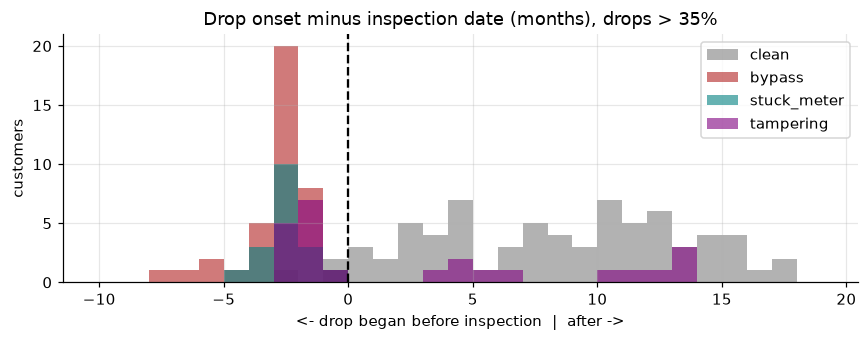

clean customers whose big drop began AFTER inspection: 66 of 72


In [36]:
lag = ((drops_full.onset - insp_date).dt.days / 30.4).round()
d = pd.DataFrame({"lag": lag, "group": group, "drop": drops_full.drop_pct}).dropna()
d = d[d["drop"] > .35]
fig, ax = plt.subplots(figsize=(8, 3.2))
for g, c in [("clean", "grey"), ("bypass", "firebrick"), ("stuck_meter", "teal"), ("tampering", "purple")]:
    ax.hist(d.lag[d.group == g], bins=np.arange(-10, 20), alpha=.6, label=g, color=c)
ax.axvline(0, c="k", ls="--"); ax.set(title="Drop onset minus inspection date (months), drops > 35%",
                                      xlabel="<- drop began before inspection  |  after ->", ylabel="customers"); ax.legend()
plt.tight_layout(); plt.show()
print("clean customers whose big drop began AFTER inspection:", (d[d.group == "clean"].lag > 0).sum(),
      "of", (d.group == "clean").sum())

In [37]:
# Does theft continue after the inspection (i.e., was it fixed)?
thief = group.isin(["bypass", "stuck_meter", "tampering", "under_billing"])
ratio = {}
for cid in group[thief].index:
    s = upto(cid, deseason)
    pre, post = s[s.index <= insp_date[cid]].tail(2), s[s.index > insp_date[cid]]
    ratio[cid] = post.median() / pre.median()
print("post-inspection usage / usage just before inspection, confirmed thieves:")
pd.Series(ratio).groupby(group).median().round(2)

post-inspection usage / usage just before inspection, confirmed thieves:


loss_type
bypass           1.02
stuck_meter      0.93
tampering        1.14
under_billing    0.89
dtype: float64

**Finding (H8 ✅, and the most important result in this notebook):**

- **Theft drops start 1–5 months *before* the inspection.** The inspector was sent because of the drop.
- **66 of the 72 big drops among "clean" customers start *after* the inspection.** They were clean when visited, and nobody knows what they are now.
- **Confirmed theft is not fixed afterwards.** Post-inspection usage is 0.9–1.1× the level just before the visit, so it stays at the stolen level. The loss is still happening, which is why confirmed customers stay on the list.

**Consequence:** if we trained or evaluated on full 24-month histories, dozens of "clean" customers would show big drops and the model would learn *"drop ⇒ clean"*, which is exactly backwards. *Decision: every evaluation in §9 uses only data up to each customer's inspection date.* The final ranking uses the full history, because that's what inspectors will act on next month.

## 7. H9: feeder losses. Do they help pick individual customers?

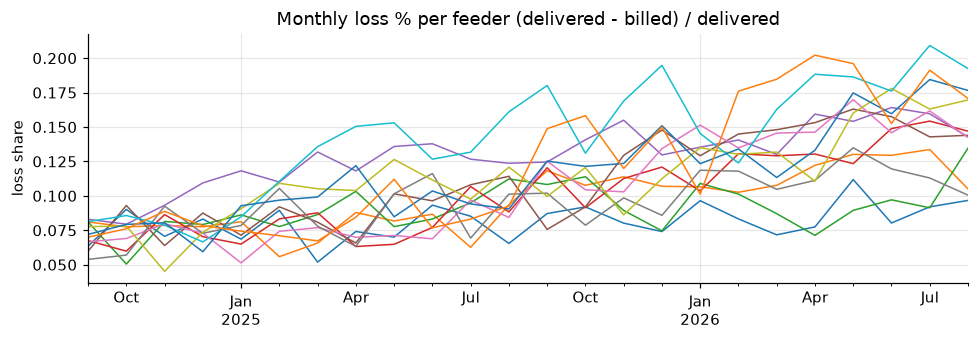

In [38]:
fig, ax = plt.subplots(figsize=(9, 3.2))
fl.loss_pct.unstack(0).plot(ax=ax, lw=1, legend=False)
ax.set(title="Monthly loss % per feeder (delivered - billed) / delivered", ylabel="loss share", xlabel="")
plt.tight_layout(); plt.show()

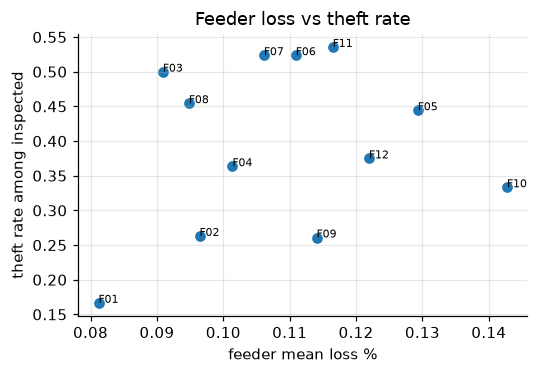

correlation: 0.19


,mean_loss,theft_rate_inspected,confirmed_thefts,customers
feeder_id,,,,
F01,0.081,0.167,2,169
F02,0.096,0.263,5,198
F03,0.091,0.500,9,161
F04,0.101,0.364,8,177
F05,0.129,0.444,8,164
F06,0.111,0.524,11,146
F07,0.106,0.524,11,151
F08,0.095,0.455,10,151
F09,0.114,0.261,6,174


In [39]:
cust_f = customers.set_index("customer_id").feeder_id
summary = pd.DataFrame({
    "mean_loss": fl.loss_pct.groupby("feeder_id").mean(),
    "theft_rate_inspected": lab.groupby("feeder_id").theft.mean(),
    "confirmed_thefts": lab.groupby("feeder_id").theft.sum(),
    "customers": cust_f.value_counts(),
})
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(summary.mean_loss, summary.theft_rate_inspected)
for f, row in summary.iterrows(): ax.annotate(f, (row.mean_loss, row.theft_rate_inspected), fontsize=7)
ax.set(xlabel="feeder mean loss %", ylabel="theft rate among inspected", title="Feeder loss vs theft rate")
plt.tight_layout(); plt.show()
print("correlation:", summary.mean_loss.corr(summary.theft_rate_inspected).round(2))
summary.round(3)

**Finding (H9 ❌ for ranking individuals):** feeder losses sit between 5% and 21% and move together month to month (seasonal, like consumption). Across the 12 feeders, the correlation between mean loss and theft rate among inspected customers is only **0.19**, each point rests on 2–15 confirmed cases, and 12 points are too few to trust. A feeder with 150+ customers also tells us nothing about *which* of those customers.

*Decision: leave feeder losses out of the score.* In the README we'd suggest using them at the operational level, for example to decide which feeder to send an inspection team to first, or to check that confirmed cases actually reduce feeder loss afterwards.

## 8. The feature table
Only features that survived §5–§7 are kept. `build_features` takes a cutoff so the same code produces point-in-time features for evaluation and full-history features for the final ranking.

In [40]:
def build_features(cutoffs=None):
    """One row per customer. cutoffs: optional Series customer_id -> last date to use."""
    rows = {}
    for cid in raw.index:
        cut = None if cutoffs is None else cutoffs.get(cid)
        ds, rw = upto(cid, deseason, cut), upto(cid, raw, cut)
        rows[cid] = dict(n_months=len(rw),
                         stuck_run=longest_identical_run(rw),
                         round_share=float((rw % 50 == 0).mean()) if len(rw) else 0.0,
                         **step_drop(ds), **on_off(ds),
                         vacant_months=int((status.loc[cid] == "vacant").sum()))
    f = pd.DataFrame(rows).T
    num = [c for c in f.columns if c != "onset"]
    f[num] = f[num].astype(float)
    f["onset"] = pd.to_datetime(f.onset)
    return f

feat_pit = build_features(insp_date)     # evaluation: what the inspector could have seen
feat_now = build_features()              # ranking: everything we know today
feat_now.describe().round(2).T

,count,mean,min,25%,50%,75%,max,std
n_months,2000.0,22.87,5.0,24.0,24.0,24.0,24.0,3.5
stuck_run,2000.0,1.35,1.0,1.0,1.0,1.0,22.0,2.12
round_share,2000.0,0.01,0.0,0.0,0.0,0.0,0.92,0.08
drop_pct,2000.0,0.17,0.0,0.01,0.07,0.21,0.96,0.22
onset,1565,2025-08-29 03:58:18.785942,2024-12-01 00:00:00,2025-01-01 00:00:00,2025-10-01 00:00:00,2026-04-01 00:00:00,2026-06-01 00:00:00,NaN
months_after,2000.0,8.99,0.0,3.0,7.0,17.0,21.0,7.7
noise_ratio,1565.0,1.73,0.01,0.75,1.21,2.2,29.1,1.68
flips,2000.0,0.91,0.0,0.0,0.0,1.0,12.0,1.93
low_months,2000.0,1.37,0.0,0.0,0.0,2.0,18.0,2.89
vacant_months,2000.0,0.55,0.0,0.0,0.0,0.0,16.0,2.39


## 9. Scoring and evaluation

**Rule-based score.** Each detector gives a 0–1 strength. A customer's risk is the strongest detector, weighted by how reliable that detector proved in §5:

| Detector | Strength | Weight (reliability) |
|---|---|---|
| stuck meter | 1 if 3+ identical readings (and not round bills) | 1.00 |
| round-number billing | round_share scaled (≥40% of months → 1) | 0.95 |
| on/off tampering | flips scaled (3 → 0, 7+ → 1) | 0.85 |
| noisy sustained drop (bypass) | drop size × noise, needs ≥3 months after | 0.80 |
| quiet sustained drop | drop size only | 0.35 (could be genuine) |

Using the *maximum* means one strong fingerprint is enough, and the reason given is the detector that fired.

In [41]:
clip01 = lambda x: np.clip(x, 0, 1)

def detector_scores(f):
    enough_after = (f.months_after >= 3).astype(float)
    drop_strength = clip01((f.drop_pct - 0.30) / 0.25) * enough_after
    noise_strength = clip01((f.noise_ratio.fillna(0) - 1.2) / 1.3)
    return pd.DataFrame({
        "stuck":   1.00 * ((f.stuck_run >= 3) & (f.round_share < 0.2)),
        "round":   0.95 * clip01(f.round_share / 0.4),
        "on_off":  0.85 * clip01((f.flips - 3) / 4),
        "bypass":  0.80 * drop_strength * noise_strength,
        "quiet_drop": 0.35 * drop_strength,
    }, index=f.index)

def rule_score(f):
    d = detector_scores(f)
    # Small tie-breaker so customers with equal max are ordered by overall evidence.
    return (d.max(axis=1) + 0.01 * d.sum(axis=1)).clip(0, 1), d.idxmax(axis=1).where(d.max(axis=1) > 0, "none")

In [42]:
labelled = group[group.isin(["clean", "bypass", "tampering", "stuck_meter", "under_billing"])
                 & ~group.index.isin(bad_insp.customer_id)].index
y = (group[labelled] != "clean").astype(int)

def precision_at_k(score, y, ks):
    order = score.loc[y.index].sort_values(ascending=False, kind="stable").index
    return pd.Series({k: y[order[:k]].mean() for k in ks})

ks = [10, 20, 30, 50, 75, 100]
score_pit, _ = rule_score(feat_pit)
results = {"rules (point-in-time)": precision_at_k(score_pit, y, ks),
           "random (base rate)": pd.Series(y.mean(), index=ks)}

In [43]:
# Baselines a utility might use today
low_usage = -feat_pit.index.to_series().map(lambda c: upto(c, raw, insp_date.get(c)).tail(3).median())
naive_drop = pd.Series({c: step_drop(raw.loc[c][raw.columns <= insp_date[c]]
                                     if pd.notna(insp_date.get(c)) else raw.loc[c])["drop_pct"] for c in labelled})
results["lowest recent usage"] = precision_at_k(low_usage, y, ks)
results["biggest raw drop"] = precision_at_k(naive_drop, y, ks)

In [44]:
# A simple learned model for comparison: logistic regression on the same features, 5-fold CV.
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_cols = ["stuck_run", "round_share", "drop_pct", "noise_ratio", "flips", "low_months", "months_after", "n_months"]
X = feat_pit.loc[labelled, X_cols].fillna(0)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, C=0.5))
cv = StratifiedKFold(5, shuffle=True, random_state=0)
lr_prob = pd.Series(cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1], index=labelled)
results["logistic regression (5-fold CV)"] = precision_at_k(lr_prob, y, ks)
res = pd.DataFrame(results)
res.round(2)

,rules (point-in-time),random (base rate),lowest recent usage,biggest raw drop,logistic regression (5-fold CV)
10,1.00,0.4,1.00,1.00,1.00
20,1.00,0.4,0.80,1.00,1.00
30,1.00,0.4,0.80,1.00,1.00
50,1.00,0.4,0.72,1.00,1.00
75,1.00,0.4,0.64,1.00,1.00
100,0.97,0.4,0.58,0.88,0.98


**The labelled set is too easy on its own.** At inspection time the clean customers hadn't dropped yet (§6.3), so even "biggest raw drop" looks nearly perfect on it. The customers that actually waste inspections, vacant premises and genuine reducers, aren't in the labelled set.

So we add a **hard-negatives test**: the 247 labels **plus the 113 uninspected vacant premises, treated as not-theft** (§6.1 showed vacancy explains their drop). These use full-history features, because that's what the ranking will see.

In [45]:
hard_neg = pd.Index(vac_ids).difference(inspections.customer_id)   # never inspected: no_access is "unknown", not innocent
y_hard = pd.concat([y, pd.Series(0, index=hard_neg)])
score_now_tmp, _ = rule_score(build_features())
naive_full = pd.Series({c: step_drop(raw.loc[c].dropna())["drop_pct"] for c in hard_neg})
low_full = -pd.Series({c: raw.loc[c].dropna().tail(3).median() for c in hard_neg})
lr_full = pd.Series(model.fit(X, y).predict_proba(build_features().loc[hard_neg, X_cols].fillna(0))[:, 1], index=hard_neg)
hard = pd.DataFrame({
    "rules": precision_at_k(pd.concat([score_pit[labelled], score_now_tmp[hard_neg]]), y_hard, ks),
    "random (base rate)": pd.Series(y_hard.mean(), index=ks),
    "lowest recent usage": precision_at_k(pd.concat([low_usage[labelled], low_full]), y_hard, ks),
    "biggest raw drop": precision_at_k(pd.concat([naive_drop, naive_full]), y_hard, ks),
    "logistic regression": precision_at_k(pd.concat([lr_prob, lr_full]), y_hard, ks),
})
hard.round(2)

,rules,random (base rate),lowest recent usage,biggest raw drop,logistic regression
10,1.00,0.28,0.00,0.0,1.00
20,1.00,0.28,0.00,0.0,1.00
30,1.00,0.28,0.00,0.0,1.00
50,0.98,0.28,0.00,0.0,0.98
75,0.97,0.28,0.00,0.0,0.99
100,0.97,0.28,0.02,0.0,0.96


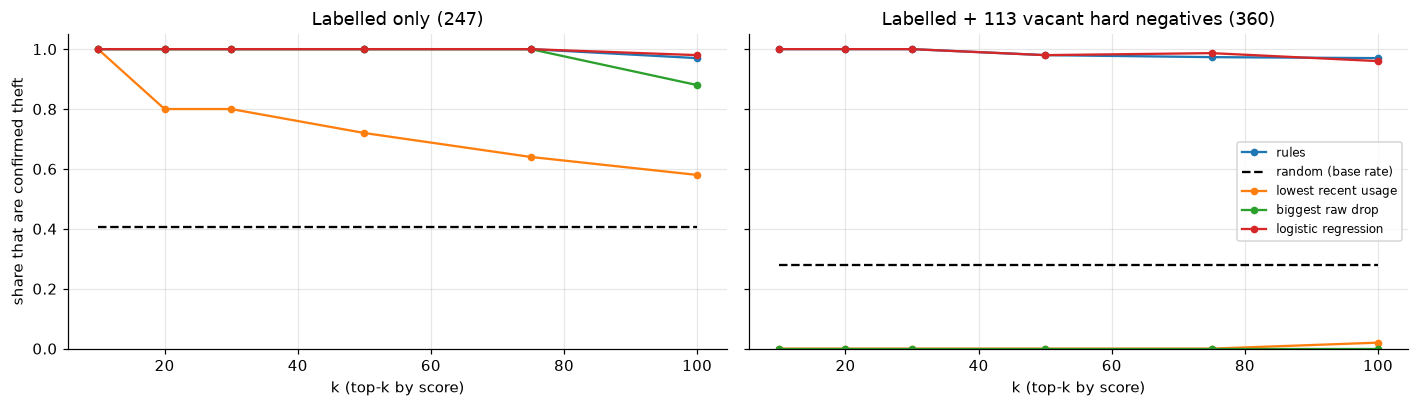

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, (tbl, title) in zip(axes, [(res, f"Labelled only ({len(y)})"), (hard, f"Labelled + {len(hard_neg)} vacant hard negatives ({len(y_hard)})")]):
    for col in tbl: ax.plot(tbl.index, tbl[col], "k--" if "random" in col else "-o", label=col, ms=4)
    ax.set(title=title, xlabel="k (top-k by score)", ylim=(0, 1.05))
axes[0].set_ylabel("share that are confirmed theft"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

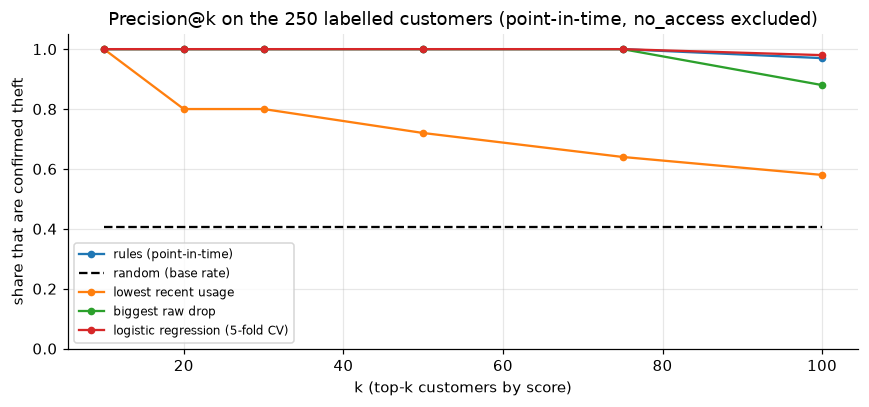

In [47]:
fig, ax = plt.subplots(figsize=(8, 3.8))
styles = {"random (base rate)": "k--"}
for col in res: ax.plot(res.index, res[col], styles.get(col, "-o"), label=col, ms=4)
ax.set(title="Precision@k on the 250 labelled customers (point-in-time, no_access excluded)",
       xlabel="k (top-k customers by score)", ylabel="share that are confirmed theft", ylim=(0, 1.05))
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

In [48]:
# Which confirmed thieves does the rule score miss, and which clean customers does it rank high?
_, reason_pit = rule_score(feat_pit)
ev = pd.DataFrame({"score": score_pit[labelled], "y": y, "group": group[labelled], "detector": reason_pit[labelled]})
top = ev.sort_values("score", ascending=False).head(100)
print("Share of each labelled group that lands in the top 100 (point-in-time):")
print((top.group.value_counts() / ev.group.value_counts()).round(2).dropna().to_dict())
print("\nDetectors that fired on clean customers:", ev[(ev.y == 0) & (ev.score > .3)].detector.value_counts().to_dict())

Share of each labelled group that lands in the top 100 (point-in-time):
{'bypass': 1.0, 'clean': 0.02, 'stuck_meter': 1.0, 'tampering': 0.88, 'under_billing': 1.0}

Detectors that fired on clean customers: {}


**Finding (evaluation):**

| Precision@100 | Labelled only | + vacant hard negatives |
|---|---|---|
| random | 0.40 | 0.28 |
| lowest recent usage | 0.58 | **0.02** |
| biggest raw drop | 0.88 | **0.00** |
| logistic regression | 0.98 | 0.96 |
| **rules** | **0.97** | **0.97** |

- **On the labels alone, almost everything looks good.** That's the §6.3 effect: clean customers hadn't dropped yet when inspected.
- **Add the realistic hard cases and the naive methods collapse.** Their top 100 fills with empty premises. The rules stay at 97%, **about 3.5× random**. The 3 misses are all tampering cases that hadn't switched on and off enough times by their inspection date.
- **Logistic regression performs the same** on these features, so the value comes from the features, not the model. *Decision: ship the rules.* They're as accurate, each reason maps directly to one detector, and they're easy to change live.

**Caveats:**

- This is precision on customers someone chose to inspect, plus vacant premises. The genuine-reducer trap from §6.2 can't be scored, because nobody has visited those customers since they dropped.
- The true share of theft among the 1,720 uninspected customers is unknown, so absolute precision on the hidden set will be lower than 97%.

## 10. The final ranking, reasons, and what goes in the README
The rules are applied to **full-history** features (what inspectors act on next month).

In [49]:
REASONS = {
    "stuck":      lambda f: f"meter has shown exactly {raw.loc[f.name].iloc[-1]:.0f} kWh for {int(f.stuck_run)} months running",
    "round":      lambda f: f"{f.round_share:.0%} of bills are round estimates, not real meter reads",
    "on_off":     lambda f: f"usage keeps switching between normal and very low ({int(f.flips)} switches)",
    "bypass":     lambda f: f"usage fell {f.drop_pct:.0%} in {f.onset:%b %Y} and has been erratic since",
    "quiet_drop": lambda f: f"usage fell {f.drop_pct:.0%} in {f.onset:%b %Y}; may be genuine, lower priority",
    "none":       lambda f: "no unusual pattern in billed usage",
}

score_now, reason_key = rule_score(feat_now)
submission = pd.DataFrame({
    "customer_id": feat_now.index,
    "risk_score": score_now.round(4).values,
    "primary_reason": [REASONS[k](feat_now.loc[c]) for c, k in reason_key.items()],
}).sort_values("risk_score", ascending=False, kind="stable").reset_index(drop=True)
submission.head(15)

,customer_id,risk_score,primary_reason
0,C100004,1.0,meter has shown exactly 28 kWh for 11 months r...
1,C100022,1.0,meter has shown exactly 182 kWh for 10 months ...
2,C100026,1.0,meter has shown exactly 530 kWh for 12 months ...
3,C100041,1.0,meter has shown exactly 64 kWh for 20 months r...
4,C100050,1.0,meter has shown exactly 96 kWh for 11 months r...
5,C100133,1.0,meter has shown exactly 95 kWh for 11 months r...
6,C100135,1.0,meter has shown exactly 100 kWh for 11 months ...
7,C100202,1.0,meter has shown exactly 133 kWh for 10 months ...
8,C100259,1.0,meter has shown exactly 54 kWh for 5 months ru...
9,C100280,1.0,meter has shown exactly 75 kWh for 11 months r...


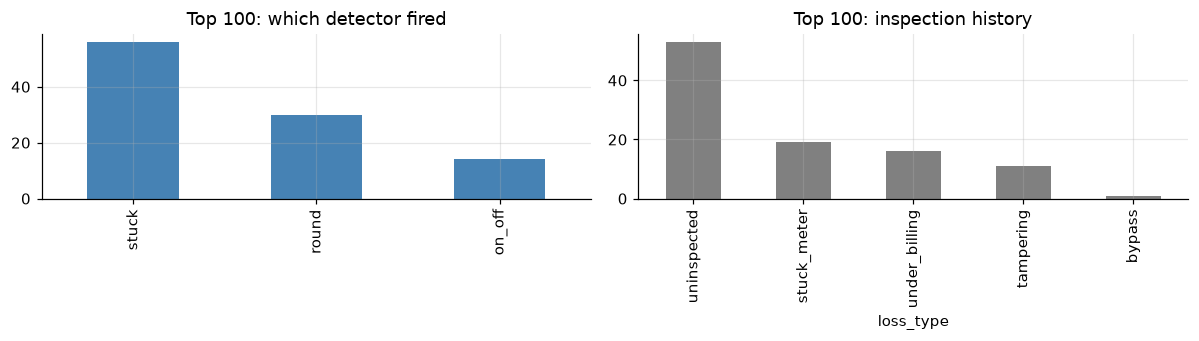

vacant customers in top 100: 0
top 100 by detector: {'stuck': 56, 'round': 30, 'on_off': 14}
top 100 by history : {'uninspected': 53, 'stuck_meter': 19, 'under_billing': 16, 'tampering': 11, 'bypass': 1}
score of 100th customer: 0.87 | customers with score > 0.5: 225


In [50]:
top100 = submission.head(100).customer_id
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
reason_key[top100].value_counts().plot.bar(ax=axes[0], color="steelblue"); axes[0].set(title="Top 100: which detector fired")
group[top100].value_counts().plot.bar(ax=axes[1], color="grey"); axes[1].set(title="Top 100: inspection history")
plt.tight_layout(); plt.show()
print("vacant customers in top 100:", top100.isin(vac_ids).sum())
print("top 100 by detector:", reason_key[top100].value_counts().to_dict())
print("top 100 by history :", group[top100].value_counts().to_dict())
print("score of 100th customer:", submission.risk_score.iloc[99], "| customers with score > 0.5:", (submission.risk_score > .5).sum())

**Finding (final ranking):**

- **The top 100 is 56 stuck meters, 30 round-number accounts and 14 on/off (tampering) patterns.** 53 of them have never been inspected. There are **0 vacant premises and 0 previously-clean customers**.
- **No bypass-style drop makes the top 100.** Stuck and round-number patterns are near-certain, while a noisy drop is strong evidence but not proof. 105 customers have a strong noisy-drop signal and rank just below, from about rank 100 to 225. This is a deliberate priority call, and the first thing to revisit when real inspection feedback arrives.
- **Scores around rank 100 are nearly tied** (0.87). Where exactly the cut falls among on/off customers is close to arbitrary.

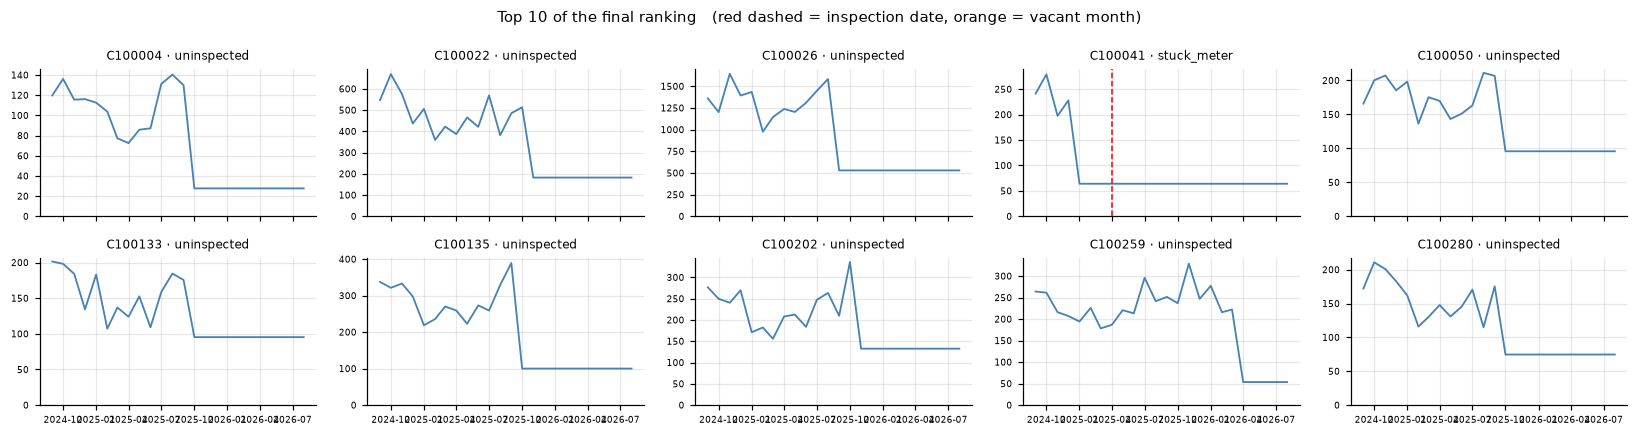

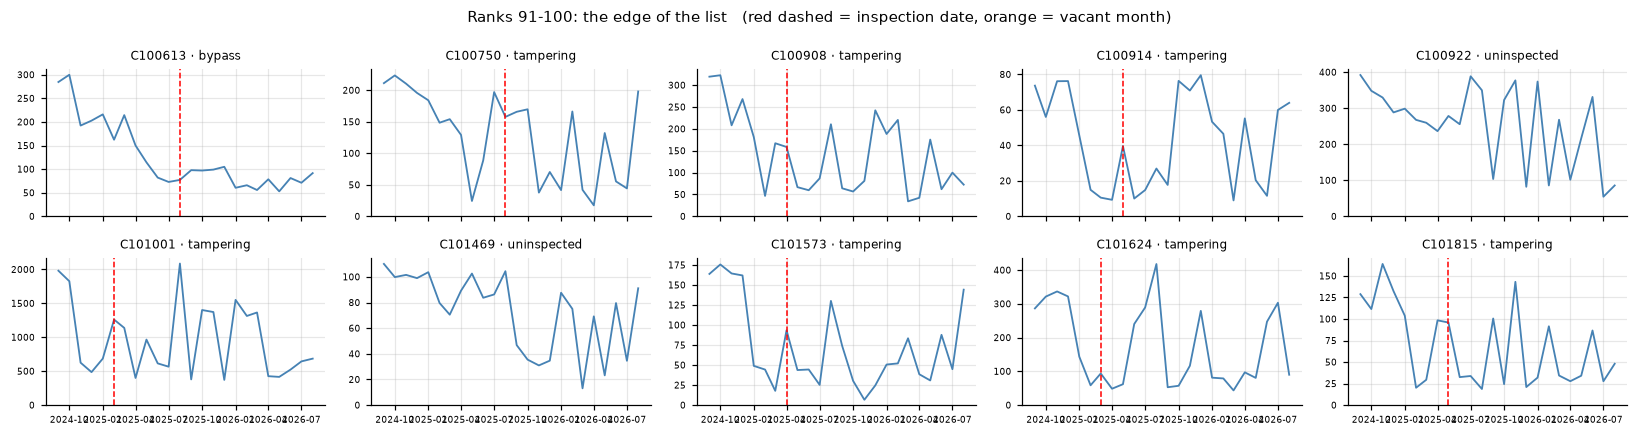

In [51]:
plot_customers(list(top100[:10]), "Top 10 of the final ranking")
plot_customers(list(top100[90:100]), "Ranks 91-100: the edge of the list")

In [52]:
# Format checks that the brief's automatic scorer will apply.
wc = submission.primary_reason.str.split().str.len()
assert list(submission.columns) == ["customer_id", "risk_score", "primary_reason"]
assert len(submission) == 2000 and submission.customer_id.is_unique
assert set(submission.customer_id) == set(customers.customer_id)
assert submission.risk_score.between(0, 1).all() and submission.risk_score.notna().all()
assert (wc < 15).all(), submission[wc >= 15]
print("all format checks pass; longest reason =", wc.max(), "words")

all format checks pass; longest reason = 11 words


## 11. Summary: what we proved, what we didn't, and what goes in the README

| # | Claim | Verdict | Evidence |
|---|---|---|---|
| H1 | Data is clean | ⚠️ mostly | §2: no nulls, dups or gaps, **but 6 inspections are dated before connection**. Scale differences and `vacant` need handling |
| H2 | Bypass = sudden sustained drop | ✅ + noisier afterwards | §5.1 |
| H3 | Stuck meter = identical readings | ✅ near-perfect | §5.2: all stuck cases have 3+ identical; no clean customer does |
| H4 | Under-billing = below peers | ❌ → round-number bills ✅ | §5.3 |
| H5 | Tampering = erratic | ⚠️ yes, but needs time to show | §5.4: 9 switches (full) vs 2 at inspection |
| H6 | Vacant ≠ theft | ✅ | §6.1: the naive ranking was full of vacant premises |
| H7 | Some drops are genuine | ✅ quiet vs noisy | §6.2 |
| H8 | Label timing matters | ✅ critical | §6.3: 66/72 clean drops started after inspection |
| H9 | Feeder loss helps rank customers | ❌ | §7 |
| H10 | Seasonality | ✅ ±20% | §4 |

**Assumptions to state in the README**

- A customer already confirmed as theft stays on the list if billing still shows the pattern. §6.3 shows the loss wasn't fixed.
- `no_access` means unknown, not clean.
- `vacant` status is trusted as recorded.
- Round-number bills are treated as a commercial-loss signal (estimated billing hides real usage), even though they could be a billing-process problem rather than theft.

**Headline for the README:** on 247 labelled customers plus 113 vacant hard negatives, 97% of the rule-based top 100 are confirmed theft, against 28% for random guessing. A naive "biggest drop" ranking scores 0%.

**Three biggest weaknesses** (draft)

1. **Few labels, chosen by inspectors.** 250 labels picked by people, 40% positive. Our precision estimate may not reflect the wider population.
2. **Theft that looks like a genuine drop, or that has no "before" period, is under-ranked.** A thief who takes a steady fraction produces a quiet drop, which scores 0.35 and falls outside the top 100. 195 uninspected customers have a quiet drop and some will be thieves. A connection bypassed from day one has no drop at all and scores 0.
3. **Hand-set thresholds.** The weights and thresholds (3 identical readings, noise ratio 1.2–2.5, 40% round bills) came from this one synthetic dataset. They need re-checking on real inspection feedback before anyone trusts them.

**Next step:** turn §4 + §8 + §9 + §10 into `score.py`, a single script run with one command.